# Assignment 2 — Classification Model Comparison

**Dataset:** UCI Dry Bean Dataset  
**Task:** Seven-class supervised classification  
**Input variables:** 16 numerical bean measurements  
**Target:** `Class` (BARBUNYA, BOMBAY, CALI, DERMASON, HOROZ, SEKER, SIRA)

## Step 1 — Dataset choice and exploratory analysis

**Objective:** Select a dataset meeting the assignment constraints and understand its structure before training.

**Problem statement:** Predict the variety of a dry bean from its measured geometric properties. This is a **multiclass** classification problem, unlike a binary yes/no classifier.

**Why this dataset?** The source dataset contains **13,611 observations**, **16 numerical predictors**, and **seven target classes**, satisfying the minimum of 500 observations and 12 features. Its class distribution and measurements allow a meaningful comparison of linear, tree-based, distance-based, probabilistic, and margin-based models.

**Procedure:** Load the Excel dataset; inspect the dimensions, data types, missingness and class frequencies; then visualize the class distribution. The actual outputs below are the evidence for the observations.

**Block 1: Dataset Loading and Exploratory Analysis**

Objective: Examine the UCI Dry Bean Dataset, verify its structure, identify data-quality issues, and understand the distribution of the seven target classes.

In [3]:
# Import Pandas for loading, cleaning, and analyzing tabular data.
import pandas as pd

# Import NumPy for numerical and array-based operations.
import numpy as np

# Import Matplotlib for creating data visualization charts.
import matplotlib.pyplot as plt

# Import OS to verify the working directory and dataset location.
import os

# Confirm that the required libraries have been imported.
print("Libraries imported successfully!")

# Verify the working directory and availability of the dataset.
# Set the BITS Virtual Lab project directory.
project_dir = (
    "/home/s2026ak05476/workspace/2026AK05476/"
    "ML_Assignment2_Dry_Bean/ML-Assignment2-Dry-Bean-main"
)

# Verify the project folder exists.
assert os.path.isdir(project_dir), "Project directory not found"

# Set the working directory to the project folder.
os.chdir(project_dir)

# Verify the working directory and dataset.
print("Working directory:", os.getcwd())
print("Dataset available:", os.path.isfile("Dry_Bean_Dataset.xlsx"))

Libraries imported successfully!
Working directory: /home/s2026ak05476/workspace/2026AK05476/ML_Assignment2_Dry_Bean/ML-Assignment2-Dry-Bean-main
Dataset available: True


In [4]:
# Read the original Dry Bean Dataset from the Excel file.
# The dataset contains 16 numerical input features and one target column.
# Each observation represents a bean described by its shape measurements.
df = pd.read_excel("Dry_Bean_Dataset.xlsx")

# Confirm successful loading and display the dataset dimensions.
# The expected shape is 13,611 rows and 17 columns.
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

# Display the first five observations to understand the dataset structure.
display(df.head())

Dataset loaded successfully!
Dataset shape: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [5]:
# Display the dataset's column names, data types, and non-null counts.
# This helps identify numerical features and the categorical target.
print("Dataset information:")
df.info()

# Check the number of missing values in every column.
# Missing values may require imputation before model training.
print("\nMissing values:")
print(df.isnull().sum())

# Count rows that are exact duplicates of earlier observations.
# Duplicate records may affect model training and evaluation.
print("\nDuplicate rows:")
print(df.duplicated().sum())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  obje

In [6]:
# Display the number of observations belonging to each bean variety.
# This helps identify class imbalance in the classification dataset.
print("Target class distribution:")
print(df["Class"].value_counts())

# Count the number of unique target categories.
# Dry Bean is a multiclass classification dataset with seven classes.
print("\nNumber of classes:")
print(df["Class"].nunique())

Target class distribution:
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

Number of classes:
7


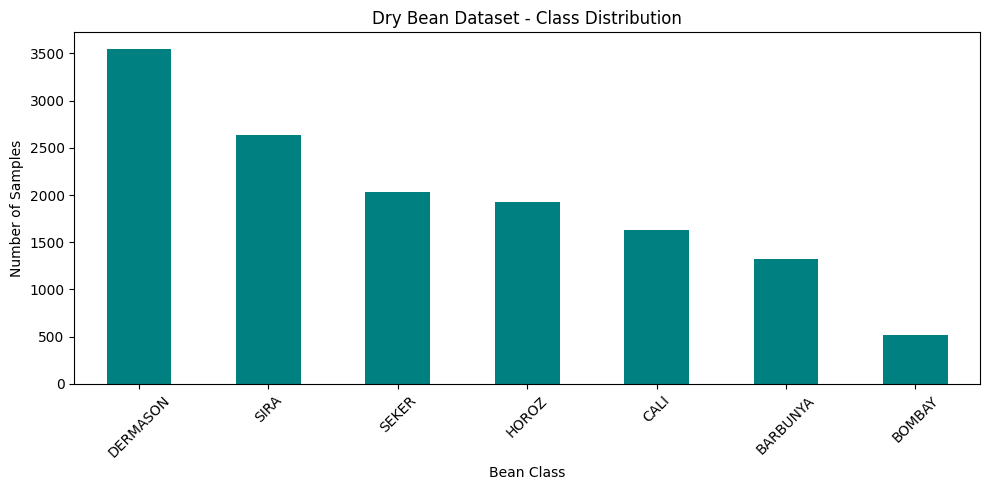

In [7]:
# Count the observations in each target class.
# The counts are arranged in descending order by default.
class_counts = df["Class"].value_counts()

# Create a figure with sufficient space for all seven class names.
plt.figure(figsize=(10, 5))

# Plot the class counts as a vertical bar chart.
# Teal is used to make the chart visually clear.
class_counts.plot(kind="bar", color="teal")

# Add a descriptive chart title and axis labels.
plt.title("Dry Bean Dataset - Class Distribution")
plt.xlabel("Bean Class")
plt.ylabel("Number of Samples")

# Rotate the class names to prevent overlapping labels.
plt.xticks(rotation=45)

# Adjust the chart layout and display the final visualization.
plt.tight_layout()
plt.show()

### Step 1 — Observations

1. The dataset includes **16 numerical input variables** and one categorical target variable, `Class`.
2. The target contains **seven bean varieties**, making the problem multiclass classification.
3. The class-frequency table and bar chart show the **actual class imbalance**; the heights should not be interpreted as equal.
4. Review the printed `df.info()` and missing-value checks above to confirm data completeness rather than assuming it.
5. The dataset meets the assignment's minimum dataset-size and feature-count requirements.

**Interpretation:** Class imbalance motivates stratified sampling and reporting class-level results alongside overall scores.

In [9]:
# Separate the 16 numerical input features from the target column.
# The target must not be included among the predictor variables.
X = df.drop(columns=["Class"])

# Store the actual bean varieties as the target variable.
y = df["Class"]

# Verify the number of observations and input features.
print("Input features shape:", X.shape)
print("Target shape:", y.shape)

# Display all input feature names used for classification.
print("\nFeature names:")
print(X.columns.tolist())

# Display the seven unique target classes in alphabetical order.
print("\nTarget classes:")
print(sorted(y.unique()))

Input features shape: (13611, 16)
Target shape: (13611,)

Feature names:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']

Target classes:
['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']


## Step 2 — Data preprocessing and test-set creation

**Objective:** Prepare a fair, reproducible evaluation dataset for all five classifiers.

**Procedure:** Remove exact duplicate records; separate the 16 predictors from `Class`; split the cleaned observations into **80% training and 20% testing**, using `random_state=42` and `stratify=y`; export a **labeled** `test_data.csv` for Streamlit evaluation.

**Why stratification?** It maintains approximately the same class proportions in the training and testing subsets, which matters because bean varieties do not occur equally often.

**Scaling and leakage prevention:** Standardization is implemented **inside the relevant scikit-learn pipelines in Step 3**, not fitted to the complete dataset beforehand. This ensures the scaler learns only from training observations. Decision Tree does not require scaling. The held-out test set is not used to fit models.

**Expected evidence:** Printed row counts, duplicate counts, train/test shapes, class proportions and a sample of the exported CSV.

**Block 2: Data Cleaning and Train/Test Preparation**

Objective: Remove exact duplicate observations, separate predictors from target labels, and create reproducible stratified training and testing subsets for fair model evaluation.

In [12]:
# Remove rows that contain identical values across all columns.
# This reduces the risk of identical records appearing in both
# training and testing datasets.
#
# reset_index(drop=True) creates a continuous row index
# without retaining the original index as an extra column.
df_clean = df.drop_duplicates().reset_index(drop=True)

# Display the original and cleaned dataset sizes.
print("Original rows:", len(df))
print("Duplicate rows removed:", len(df) - len(df_clean))
print("Cleaned rows:", len(df_clean))

# Confirm that no exact duplicate rows remain.
print("Remaining duplicates:", df_clean.duplicated().sum())

Original rows: 13611
Duplicate rows removed: 68
Cleaned rows: 13543
Remaining duplicates: 0


In [13]:
# Create the input feature matrix from the cleaned dataset.
# All 16 numerical features will be used for model training.
X = df_clean.drop(columns=["Class"])

# Extract the target labels from the cleaned dataset.
# Each label identifies one of the seven bean varieties.
y = df_clean["Class"]

# Verify the dimensions after duplicate removal.
print("Input features:", X.shape)
print("Target labels:", y.shape)

# Confirm that all seven classification categories are retained.
print("Number of classes:", y.nunique())

Input features: (13543, 16)
Target labels: (13543,)
Number of classes: 7


In [14]:
# Import the function used to divide the dataset.
from sklearn.model_selection import train_test_split

# Split the cleaned dataset into training and testing subsets.
#
# test_size=0.20:
#   Reserve 20% of observations for independent testing.
#
# random_state=42:
#   Make the random split reproducible.
#
# stratify=y:
#   Preserve approximately the same class proportions in both subsets.
#
# The test dataset must not be used to fit the classifiers.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Verify the number of observations in each subset.
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training features: (10834, 16)
Testing features: (2709, 16)
Training labels: (10834,)
Testing labels: (2709,)


In [15]:
# Calculate the percentage of each bean class in the cleaned dataset.
# Compare these percentages with the training and testing subsets.
#
# normalize=True converts class counts into proportions.
# Multiplying by 100 expresses the proportions as percentages.
comparison = pd.DataFrame({
    "Original %": y.value_counts(normalize=True) * 100,
    "Training %": y_train.value_counts(normalize=True) * 100,
    "Testing %": y_test.value_counts(normalize=True) * 100
}).round(2)

# Display the class percentages for all three datasets.
# Similar percentages indicate successful stratified sampling.
display(comparison)

,Original %,Training %,Testing %
Class,,,
DERMASON,26.18,26.19,26.17
SIRA,19.46,19.47,19.45
SEKER,14.97,14.96,14.99
HOROZ,13.73,13.73,13.73
CALI,12.04,12.04,12.03
BARBUNYA,9.76,9.76,9.78
BOMBAY,3.85,3.86,3.84


In [16]:
# Create a copy of the held-out testing features.
# Using copy() keeps the original X_test unchanged.
test_data = X_test.copy()

# Add the actual class labels to the test dataset.
# Streamlit will use these labels to evaluate model predictions.
# The Class column must never be passed as an input feature.
test_data["Class"] = y_test

# Export the labeled test dataset as a CSV file.
# index=False prevents the Pandas index from becoming an extra column.
test_data.to_csv("test_data.csv", index=False)

# Confirm that the CSV file has been generated.
print("Test CSV saved successfully!")
print("Shape:", test_data.shape)

# Preview the first five rows of the test dataset.
display(test_data.head())

Test CSV saved successfully!
Shape: (2709, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
1223,40512,737.636,248.202030,208.525152,1.190274,0.542365,40973,227.115566,0.744268,0.988749,0.935641,0.915043,0.006127,0.002650,0.837304,0.996621,SEKER
11769,31890,660.655,250.417300,162.522502,1.540816,0.760783,32240,201.503372,0.801962,0.989144,0.918153,0.804670,0.007853,0.002031,0.647494,0.997670,DERMASON
12059,33107,671.869,244.728317,172.938116,1.415121,0.707560,33506,205.312303,0.798683,0.988092,0.921638,0.838940,0.007392,0.002259,0.703820,0.995990,DERMASON
7126,61684,984.878,412.115648,191.473280,2.152340,0.885515,62303,280.247227,0.784724,0.990065,0.799130,0.680021,0.006681,0.000881,0.462428,0.995303,HOROZ
638,37189,700.253,243.343401,194.910062,1.248491,0.598708,37534,217.601713,0.784826,0.990808,0.953047,0.894217,0.006543,0.002581,0.799623,0.998322,SEKER


### Step 2 — Observations

1. The printed duplicate count records how many exact duplicates were removed; **use the cleaned row count** when reporting the train/test sizes.
2. `X_train` and `X_test` contain the same 16 predictor columns; `y_train` and `y_test` contain the seven-class target.
3. The split uses **80% training / 20% testing** with reproducible, stratified sampling.
4. The displayed class-percentage table lets us verify that training and test class proportions remain close to the cleaned dataset.
5. `test_data.csv` contains the test predictors **plus the true `Class` label**, allowing the deployed app to compute metrics.
6. Feature scaling is fitted within the model pipelines in the next step, avoiding information leakage from the test data.

In [18]:
from pathlib import Path

# Locate the test dataset in the project directory.
test_file = Path("test_data.csv")

# Verify that the file exists.
assert test_file.is_file(), "ERROR: test_data.csv not found"

print("PASS: Labeled test dataset is available")
print("File location:", test_file.resolve())
print("File size:", round(test_file.stat().st_size / 1024, 2), "KB")

PASS: Labeled test dataset is available
File location: /home/s2026ak05476/workspace/2026AK05476/ML_Assignment2_Dry_Bean/ML-Assignment2-Dry-Bean-main/test_data.csv
File size: 741.18 KB


## Step 3 — Define and train five classification algorithms

**Objective:** Train the five required classifiers using the **same training set**, save the fitted pipelines, and verify that they can predict without retraining.

### Classifier concepts and implementation choices

| Classifier | How it predicts | Configuration used in this notebook | Important consideration |
|---|---|---|---|
| **Logistic Regression** | Learns linear class scores and converts them to class probabilities (multiclass softmax) | `StandardScaler`, `LogisticRegression(max_iter=2000, random_state=42)` | Interpretable linear baseline; scaling helps optimization |
| **Decision Tree** | Recursively splits features using decision rules | `DecisionTreeClassifier(max_depth=12, random_state=42)` | Captures nonlinear rules; depth limit controls complexity |
| **K-Nearest Neighbors** | Uses the labels of the five nearest training samples | `StandardScaler`, `KNeighborsClassifier(n_neighbors=5)` | Distances are sensitive to feature scales |
| **Gaussian Naive Bayes** | Uses Bayes' rule and class-conditional Gaussian feature distributions | `StandardScaler`, `GaussianNB()` | Assumes conditional independence of features given the class |
| **Support Vector Machine** | Learns separating boundaries using an RBF kernel | `StandardScaler`, `SVC(kernel='rbf', probability=True, random_state=42)` | Handles nonlinear separation; probabilities support AUC |

### Key mathematical ideas

- **Multiclass logistic regression:** A softmax function converts linear class scores into probabilities that sum to one.
- **KNN:** Euclidean distance measures how close two standardized observations are.
- **Naive Bayes:** Bayes' theorem combines prior class probabilities with class-conditional feature likelihoods.
- **SVM:** The RBF kernel allows nonlinear decision boundaries by comparing feature-space distances.

**Observation guidance:** Training completion confirms fitting succeeded; it does **not** prove generalization. The held-out evaluation in Step 4 provides the actual performance evidence.

**Block 3**

In [21]:
# Verify that the cleaned dataset was split correctly.
# All five classifiers must use the same training observations
# to ensure a fair comparison of their performance.

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

# Confirm that the dataset dimensions match our expected split.
# The cleaned dataset contains 13,543 observations.
# 80% are reserved for training and 20% for testing.
assert X_train.shape == (10834, 16)
assert X_test.shape == (2709, 16)
assert y_train.shape == (10834,)
assert y_test.shape == (2709,)

# Verify that the target column is not included in the input features.
assert "Class" not in X_train.columns

print("\nDataset split verified successfully!")

Training features: (10834, 16)
Testing features: (2709, 16)
Training labels: (10834,)
Testing labels: (2709,)

Dataset split verified successfully!


In [22]:
# Import Pipeline to combine preprocessing and classification
# into a single reusable model object.
from sklearn.pipeline import Pipeline

# Import StandardScaler to standardize numerical features.
# Scaling is particularly important for distance-based algorithms.
from sklearn.preprocessing import StandardScaler

# Import the five classification algorithms required by the assignment.
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

# Import joblib to save and reload trained models.
import joblib

# Import os for creating folders and managing file paths.
import os

# Import time to measure model training duration.
import time

# Import sklearn to record the library version.
import sklearn

print("Scikit-learn version:", sklearn.__version__)
print("All classification libraries imported successfully!")

Scikit-learn version: 1.9.1
All classification libraries imported successfully!


In [23]:
# Define all five classifiers in a dictionary.
# This allows us to train and evaluate them using a common workflow.
#
# Pipelines ensure that StandardScaler is fitted only on training data.
# The same fitted scaler will later transform new test observations.

models = {

    # Logistic Regression:
    # StandardScaler standardizes the 16 numerical features.
    # max_iter=2000 allows additional iterations for convergence.
    # The classifier supports the seven bean categories.
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]),

    # Decision Tree:
    # A tree learns feature-based splitting rules.
    # Scaling is unnecessary because trees use threshold comparisons.
    # max_depth=12 limits tree complexity to reduce overfitting.
    "Decision Tree": Pipeline([
        ("classifier", DecisionTreeClassifier(
            max_depth=12,
            random_state=42
        ))
    ]),

    # K-Nearest Neighbors:
    # KNN predicts a class using nearby training observations.
    # Scaling prevents large-valued features from dominating distances.
    # n_neighbors=5 uses the five nearest training observations.
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(
            n_neighbors=5
        ))
    ]),

    # Naive Bayes:
    # GaussianNB models each feature using a class-specific
    # Gaussian distribution and assumes conditional independence.
    # Scaling is optional for GaussianNB but is included here.
    "Naive Bayes": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", GaussianNB())
    ]),

    # Support Vector Machine:
    # StandardScaler is important because SVM is sensitive
    # to differences in numerical feature scales.
    # The RBF kernel allows nonlinear classification boundaries.
    # probability=True enables probability estimates for ROC-AUC.
    # It also increases training time.
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            kernel="rbf",
            probability=True,
            random_state=42
        ))
    ])
}

# Verify that all five required models have been defined.
print("Number of classifiers:", len(models))

# Display the classifier names.
for name in models:
    print("-", name)

Number of classifiers: 5
- Logistic Regression
- Decision Tree
- KNN
- Naive Bayes
- SVM


In [24]:
# Create dictionaries to store the trained pipelines
# and the time required to train each classifier.
trained_models = {}
training_times = {}

# Train each model using the same training dataset.
for name, model in models.items():

    # Display the name of the classifier being trained.
    print(f"Training {name}...")

    # Record the starting time before training.
    start_time = time.time()

    # Fit the pipeline using training features and labels only.
    # The held-out testing dataset is not used for fitting.
    model.fit(X_train, y_train)

    # Calculate the total training time in seconds.
    elapsed = time.time() - start_time

    # Store the fitted pipeline for later evaluation and saving.
    trained_models[name] = model

    # Store the training duration for comparison.
    training_times[name] = elapsed

    # Display the training completion message.
    print(f"Completed in {elapsed:.2f} seconds\n")

# Confirm that all five classifiers have been trained.
print("All five classifiers trained successfully!")

Training Logistic Regression...
Completed in 2.58 seconds

Training Decision Tree...
Completed in 0.34 seconds

Training KNN...
Completed in 0.02 seconds

Training Naive Bayes...
Completed in 0.02 seconds

Training SVM...


/home/cloud/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Completed in 6.48 seconds

All five classifiers trained successfully!


### Step 3 — Training observations

1. The code fits **five different classifiers** to exactly the same `X_train` and `y_train`.
2. Logistic Regression, KNN, Naive Bayes and SVM include `StandardScaler` in their pipelines; Decision Tree uses raw features because threshold splits do not depend on feature units.
3. KNN uses **five neighbors**; the Decision Tree has a **maximum depth of 12**; SVM uses an **RBF kernel**.
4. The training-time output shows the computational cost of fitting each model on this runtime. Training time is **not** a measure of classification quality.
5. The next cells save the fitted pipelines, reload them and verify predictions on held-out examples.

In [26]:
# Create a folder for storing trained model files.
# exist_ok=True avoids errors if the folder already exists.
os.makedirs("models", exist_ok=True)

# Assign a separate filename to each classification model.
# These filenames will also be used by the Streamlit application.
model_filenames = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "SVM": "svm.joblib"
}

# Save each trained pipeline as a joblib file.
for name, model in trained_models.items():

    # Construct the complete output path.
    filepath = os.path.join("models", model_filenames[name])

    # Serialize the fitted pipeline to disk.
    # This preserves the model and its preprocessing parameters.
    joblib.dump(model, filepath)

    # Display the saved filename.
    print(f"Saved: {filepath}")

# Confirm that all five models were saved.
print("\nAll model files saved successfully!")

Saved: models/logistic_regression.joblib
Saved: models/decision_tree.joblib
Saved: models/knn.joblib
Saved: models/naive_bayes.joblib
Saved: models/svm.joblib

All model files saved successfully!


In [27]:
# Select the first five observations from the held-out test set.
# These observations will be used only to verify prediction functionality.
sample = X_test.head(5)

# Load each saved model and generate sample predictions.
for name, filename in model_filenames.items():

    # Construct the location of the saved model.
    filepath = os.path.join("models", filename)

    # Load the fitted pipeline from disk.
    # No training or fitting occurs during this operation.
    loaded_model = joblib.load(filepath)

    # Predict the bean class for the five test observations.
    predictions = loaded_model.predict(sample)

    # Display the predictions and their count.
    print(f"\n{name}")
    print("Predictions:", predictions)
    print("Number of predictions:", len(predictions))


Logistic Regression
Predictions: ['SEKER' 'DERMASON' 'DERMASON' 'HOROZ' 'SEKER']
Number of predictions: 5

Decision Tree
Predictions: ['SEKER' 'DERMASON' 'DERMASON' 'HOROZ' 'SEKER']
Number of predictions: 5

KNN
Predictions: ['SEKER' 'DERMASON' 'DERMASON' 'HOROZ' 'SEKER']
Number of predictions: 5

Naive Bayes
Predictions: ['SEKER' 'DERMASON' 'DERMASON' 'HOROZ' 'SEKER']
Number of predictions: 5

SVM
Predictions: ['SEKER' 'DERMASON' 'DERMASON' 'HOROZ' 'SEKER']
Number of predictions: 5


In [28]:
# Import sys to identify the Python interpreter version.
import sys

# Display the Python version used for model training.
print("Python:", sys.version.split()[0])

# Display the installed Scikit-learn version.
# Saved models should be loaded with a compatible version.
print("Scikit-learn:", sklearn.__version__)

# Display the versions of the data-processing libraries.
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

# Display the joblib version used for model serialization.
print("Joblib:", joblib.__version__)

Python: 3.12.7
Scikit-learn: 1.9.1
Pandas: 2.2.3
NumPy: 2.5.4
Joblib: 1.4.2


In [29]:
import shutil
from pathlib import Path
import zipfile

# Verify the models folder exists.
models_dir = Path("models")

assert models_dir.is_dir(), "ERROR: models folder not found"

# Verify all five trained model files.
model_files = [
    "logistic_regression.joblib",
    "decision_tree.joblib",
    "knn.joblib",
    "naive_bayes.joblib",
    "svm.joblib"
]

for filename in model_files:
    assert (models_dir / filename).is_file(), f"Missing model: {filename}"
    print(f"PASS: {filename}")

# Create a ZIP containing the models folder.
zip_path = shutil.make_archive(
    "dry_bean_models",
    "zip",
    root_dir=".",
    base_dir="models"
)

# Verify ZIP contents.
with zipfile.ZipFile(zip_path) as archive:
    assert all(
        f"models/{filename}" in archive.namelist()
        for filename in model_files
    ), "ZIP is missing one or more model files"

print("\nPASS: All five trained models packaged successfully")
print("ZIP location:", Path(zip_path).resolve())
print("ZIP size:", round(Path(zip_path).stat().st_size / (1024 * 1024), 2), "MB")

PASS: logistic_regression.joblib
PASS: decision_tree.joblib
PASS: knn.joblib
PASS: naive_bayes.joblib
PASS: svm.joblib

PASS: All five trained models packaged successfully
ZIP location: /home/s2026ak05476/workspace/2026AK05476/ML_Assignment2_Dry_Bean/ML-Assignment2-Dry-Bean-main/dry_bean_models.zip
ZIP size: 1.6 MB


In [30]:
# Verify that all five saved pipelines can be loaded successfully.
# Use only model files generated by your own training notebook.

for name, filename in model_filenames.items():

    # Load the previously trained pipeline from the models folder.
    model_path = os.path.join("models", filename)
    loaded_model = joblib.load(model_path)

    # Generate predictions on five held-out test observations.
    # This does not retrain the classifier.
    predictions = loaded_model.predict(X_test.head(5))

    # Verify that the model returns one prediction per observation.
    assert len(predictions) == 5

    # Verify that every prediction belongs to a known bean class.
    assert set(predictions).issubset(set(y_train.unique()))

    print(f"{name}: PASS")
    print("Predictions:", predictions)
    print()

Logistic Regression: PASS
Predictions: ['SEKER' 'DERMASON' 'DERMASON' 'HOROZ' 'SEKER']

Decision Tree: PASS
Predictions: ['SEKER' 'DERMASON' 'DERMASON' 'HOROZ' 'SEKER']

KNN: PASS
Predictions: ['SEKER' 'DERMASON' 'DERMASON' 'HOROZ' 'SEKER']

Naive Bayes: PASS
Predictions: ['SEKER' 'DERMASON' 'DERMASON' 'HOROZ' 'SEKER']

SVM: PASS
Predictions: ['SEKER' 'DERMASON' 'DERMASON' 'HOROZ' 'SEKER']



### Step 3 — Model export and verification observations

1. Each saved `.joblib` file contains the fitted classifier and its preprocessing pipeline, where applicable.
2. Reloading each pipeline and generating five predictions demonstrates that the saved artifacts can be used **without retraining**.
3. The assertions check output length and that predicted labels belong to the known classes.
4. These checks establish basic inference readiness; the next section evaluates performance on the **full held-out test set**.

## Step 4 — Evaluate and compare classifiers

**Objective:** Measure predictive performance on the **same untouched test split** using the six assignment metrics, inspect class-specific errors, and compare the five models.

### Metrics and interpretation

| Metric | Meaning | Interpretation |
|---|---|---|
| Accuracy | Fraction of all correct predictions | Overall correctness; may obscure minority-class errors |
| AUC | Area under ROC curve | Measures class discrimination using predicted probabilities |
| Precision | Correct positive predictions relative to predicted positives | Penalizes false-positive assignments |
| Recall | Correctly identified instances relative to actual instances | Penalizes missed class members |
| F1 | Harmonic mean of precision and recall | Balances precision and recall |
| MCC | Correlation-based measure of prediction agreement | Useful complementary summary of multiclass classification |

**Important:** The **notebook's comparison table uses macro averaging** for multiclass AUC (One-vs-Rest), Precision, Recall and F1, giving every bean class equal weight. The Streamlit application may use **weighted averaging**; these are different aggregation choices and can yield different values. Label each result clearly instead of treating the values as interchangeable.

**Confusion matrix:** Rows represent actual classes and columns predicted classes. Diagonal entries are correct predictions; off-diagonal entries reveal which varieties are confused.

**Model selection:** Compare all six metrics, not accuracy alone. Macro F1 is a reasonable primary measure when performance across all seven classes matters; explain any trade-offs with AUC, MCC and class-level recall.

**Block 4**

In [34]:
# Import the six evaluation metrics required by ML Assignment 2.
# These metrics help assess classifier performance from different perspectives.

from sklearn.metrics import (
    accuracy_score,             # Proportion of correctly classified observations
    roc_auc_score,              # Ability to distinguish between target classes
    precision_score,            # Correct predictions among predicted class members
    recall_score,               # Correctly identified members of each actual class
    f1_score,                   # Harmonic mean of precision and recall
    matthews_corrcoef          # Balanced correlation-based classification metric
)

# Import additional functions for detailed model evaluation.
from sklearn.metrics import confusion_matrix, classification_report

# Import Pandas to organize model evaluation results in a table.
import pandas as pd

print("All evaluation libraries imported successfully!")

All evaluation libraries imported successfully!


In [35]:
# Create an empty list to collect the evaluation results.
evaluation_results = []

# Evaluate all five previously trained classifiers on the same test dataset.
for name, filename in model_filenames.items():

    # Load the saved model pipeline without retraining it.
    model_path = os.path.join("models", filename)
    model = joblib.load(model_path)

    # Predict the bean classes for the held-out test observations.
    y_pred = model.predict(X_test)

    # Obtain class probabilities for multiclass ROC-AUC calculation.
    # The probability columns correspond to model.classes_.
    y_prob = model.predict_proba(X_test)

    # Calculate accuracy using all test observations.
    accuracy = accuracy_score(y_test, y_pred)

    # Calculate multiclass ROC-AUC using the One-vs-Rest approach.
    # Macro averaging gives equal importance to each of the seven classes.
    auc = roc_auc_score(
        y_test,
        y_prob,
        labels=model.classes_,
        multi_class="ovr",
        average="macro"
    )

    # Calculate macro-averaged precision across all seven classes.
    precision = precision_score(
        y_test, y_pred, average="macro", zero_division=0
    )

    # Calculate macro-averaged recall across all seven classes.
    recall = recall_score(
        y_test, y_pred, average="macro", zero_division=0
    )

    # Calculate macro-averaged F1 Score across all seven classes.
    f1 = f1_score(
        y_test, y_pred, average="macro", zero_division=0
    )

    # Calculate multiclass Matthews Correlation Coefficient.
    mcc = matthews_corrcoef(y_test, y_pred)

    # Store the calculated metrics for this classifier.
    evaluation_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "AUC": auc,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "MCC": mcc
    })

    # Display a confirmation message after evaluating each model.
    print(f"{name}: Evaluation completed")

# Convert the collected results into a comparison table.
results_df = pd.DataFrame(evaluation_results)

# Display all six metrics rounded to four decimal places.
display(results_df.round(4))

Logistic Regression: Evaluation completed
Decision Tree: Evaluation completed
KNN: Evaluation completed
Naive Bayes: Evaluation completed
SVM: Evaluation completed


,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.9192,0.9947,0.9307,0.9300,0.9302,0.9023
1,Decision Tree,0.9011,0.9621,0.9161,0.9162,0.9161,0.8804
2,KNN,0.9155,0.9832,0.9290,0.9256,0.9270,0.8978
3,Naive Bayes,0.8970,0.9911,0.9081,0.9082,0.9072,0.8762
4,SVM,0.9210,0.9945,0.9342,0.9317,0.9328,0.9045


### Step 4 — Reading the comparison table

The displayed table contains **observed** Accuracy, macro OvR AUC, macro Precision, macro Recall, macro F1 and MCC for each classifier. Higher values generally indicate better performance, but the metrics answer different questions. Macro scores treat all seven classes equally.

**Do not infer a best model from training speed or a single example prediction.** The following confusion matrices and classification reports show where each classifier succeeds or fails by bean variety.

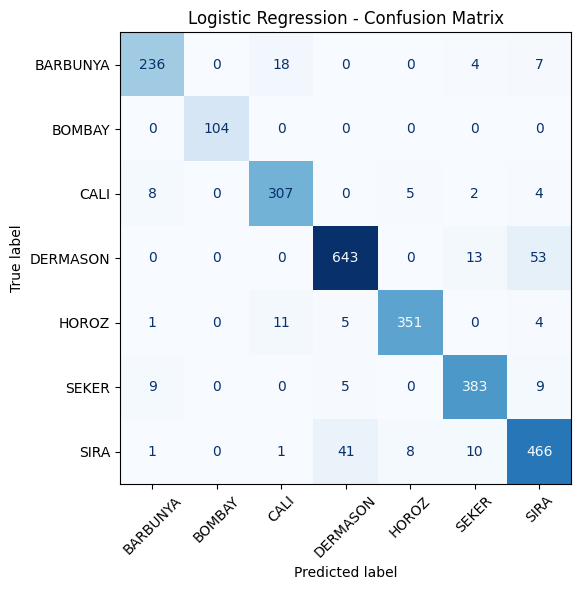


Logistic Regression - Classification Report
              precision    recall  f1-score   support

    BARBUNYA       0.93      0.89      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.91      0.94      0.93       326
    DERMASON       0.93      0.91      0.92       709
       HOROZ       0.96      0.94      0.95       372
       SEKER       0.93      0.94      0.94       406
        SIRA       0.86      0.88      0.87       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709

----------------------------------------------------------------------


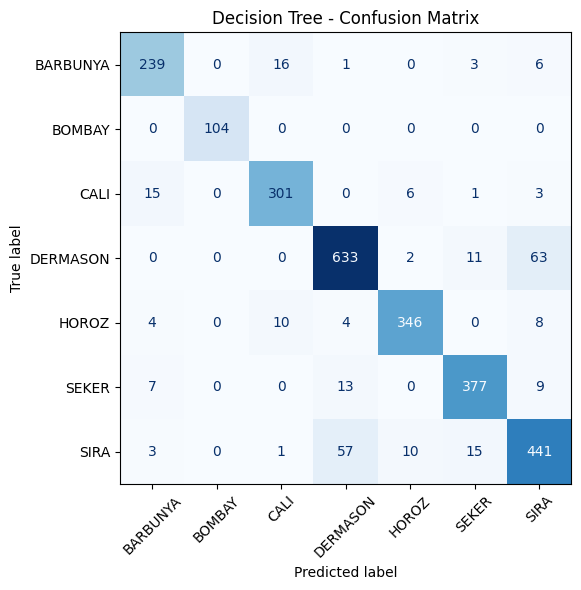


Decision Tree - Classification Report
              precision    recall  f1-score   support

    BARBUNYA       0.89      0.90      0.90       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.92      0.92       326
    DERMASON       0.89      0.89      0.89       709
       HOROZ       0.95      0.93      0.94       372
       SEKER       0.93      0.93      0.93       406
        SIRA       0.83      0.84      0.83       527

    accuracy                           0.90      2709
   macro avg       0.92      0.92      0.92      2709
weighted avg       0.90      0.90      0.90      2709

----------------------------------------------------------------------


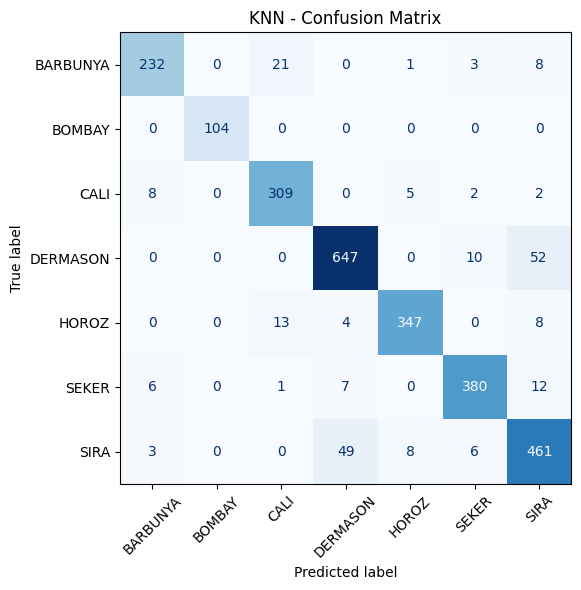


KNN - Classification Report
              precision    recall  f1-score   support

    BARBUNYA       0.93      0.88      0.90       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.90      0.95      0.92       326
    DERMASON       0.92      0.91      0.91       709
       HOROZ       0.96      0.93      0.95       372
       SEKER       0.95      0.94      0.94       406
        SIRA       0.85      0.87      0.86       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709

----------------------------------------------------------------------


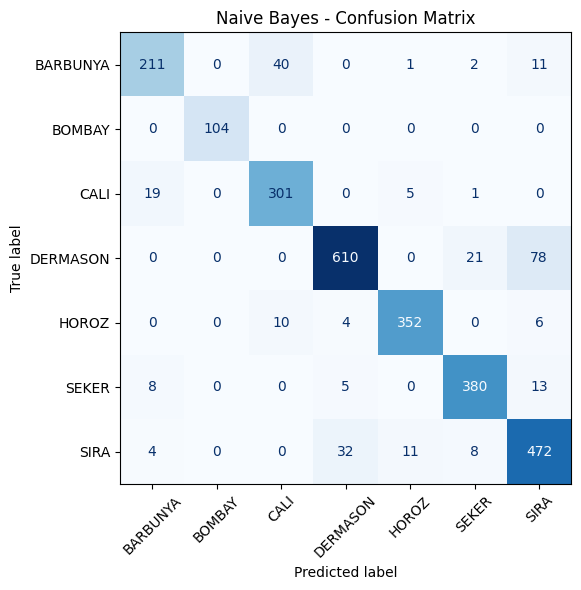


Naive Bayes - Classification Report
              precision    recall  f1-score   support

    BARBUNYA       0.87      0.80      0.83       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.86      0.92      0.89       326
    DERMASON       0.94      0.86      0.90       709
       HOROZ       0.95      0.95      0.95       372
       SEKER       0.92      0.94      0.93       406
        SIRA       0.81      0.90      0.85       527

    accuracy                           0.90      2709
   macro avg       0.91      0.91      0.91      2709
weighted avg       0.90      0.90      0.90      2709

----------------------------------------------------------------------


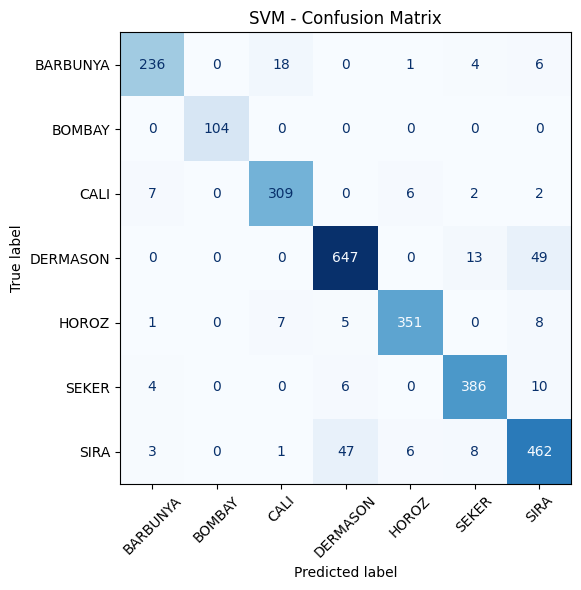


SVM - Classification Report
              precision    recall  f1-score   support

    BARBUNYA       0.94      0.89      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.95      0.93       326
    DERMASON       0.92      0.91      0.92       709
       HOROZ       0.96      0.94      0.95       372
       SEKER       0.93      0.95      0.94       406
        SIRA       0.86      0.88      0.87       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709

----------------------------------------------------------------------


In [37]:
# Import tools for displaying confusion matrices.
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Obtain the seven class labels in a consistent order.
class_names = sorted(y_test.unique())

# Generate a confusion matrix for each saved classifier.
for name, filename in model_filenames.items():

    # Load the saved model without retraining.
    model_path = os.path.join("models", filename)
    model = joblib.load(model_path)

    # Predict the classes of the held-out test observations.
    y_pred = model.predict(X_test)

    # Calculate the confusion matrix using a fixed class order.
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_names
    )

    # Create a readable confusion matrix visualization.
    fig, ax = plt.subplots(figsize=(8, 6))

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    # Display the number of observations in each matrix cell.
    display_cm.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        xticks_rotation=45,
        colorbar=False
    )

    # Add the model name to distinguish the five matrices.
    ax.set_title(f"{name} - Confusion Matrix")

    # Adjust layout to prevent labels from overlapping.
    plt.tight_layout()
    plt.show()

    # Display detailed precision, recall, F1 and support per class.
    print(f"\n{name} - Classification Report")

    print(classification_report(
        y_test,
        y_pred,
        labels=class_names,
        zero_division=0
    ))

    print("-" * 70)

### Step 4 — Confusion matrix and classification report observations

1. Each classifier has a **7 × 7 confusion matrix** corresponding to the seven bean classes.
2. A large diagonal count indicates correct classification for that bean variety; an off-diagonal count identifies a specific misclassification pattern.
3. The classification report provides per-class **precision, recall, F1 and support**; this reveals behavior hidden by overall accuracy.
4. Compare which bean pairs are confused most often and whether smaller classes have lower recall.
5. The model comparison heatmap below provides a compact six-metric summary; interpret it together with these class-level diagnostics.

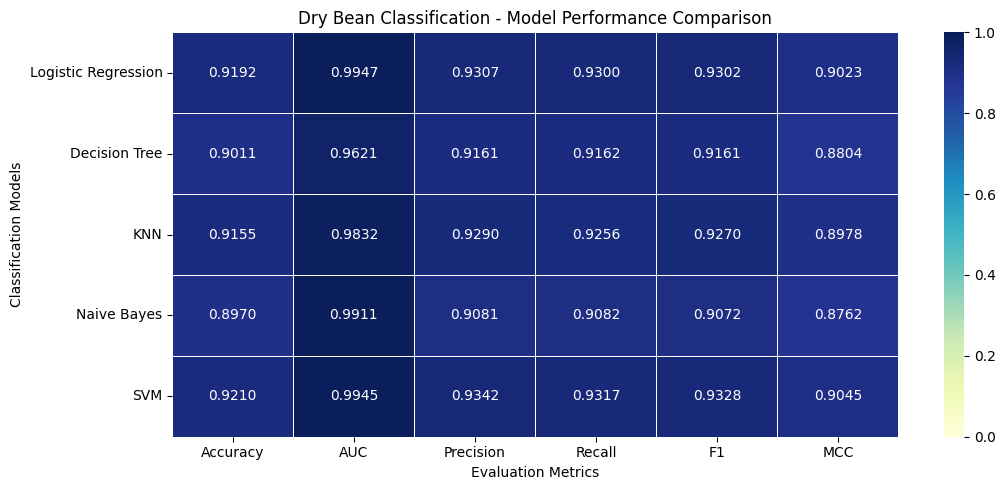

In [39]:
# Import Seaborn for creating a model comparison heatmap.
import seaborn as sns

# Select the six evaluation metrics required by the assignment.
metric_columns = [
    "Accuracy",
    "AUC",
    "Precision",
    "Recall",
    "F1",
    "MCC"
]

# Set classifier names as the row labels.
# Keep only the six metric columns for comparison.
heatmap_data = results_df.set_index("Model")[metric_columns]

# Create a figure large enough to display all five models.
plt.figure(figsize=(11, 5))

# Draw the heatmap with metric values shown inside each cell.
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".4f",
    cmap="YlGnBu",
    linewidths=0.5,
    vmin=0,
    vmax=1
)

# Add a descriptive title and axis labels.
plt.title("Dry Bean Classification - Model Performance Comparison")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Classification Models")

# Prevent overlapping text and display the chart.
plt.tight_layout()
plt.show()

### Step 4 — Final comparison observations

The heatmap visualizes the **same numerical results** shown in the comparison table; it is not a separate evaluation. Review both the overall and class-level scores when selecting the strongest classifier.

The next code cell prints a **data-driven model ranking and the measured score differences**. This avoids inserting unsupported fixed metric values into the notebook.

In [41]:
# Evidence-based observations: computed from the actual evaluation table.
ranked = results_df.sort_values(["F1", "MCC", "Accuracy"], ascending=False).reset_index(drop=True)
print("MODEL RANKING (macro F1, then MCC and Accuracy)")
display(ranked[["Model", "Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]].round(4))

best = ranked.iloc[0]
runner_up = ranked.iloc[1]
print(f"Best model by macro F1: {best['Model']} (F1 = {best['F1']:.4f})")
print(f"Runner-up: {runner_up['Model']} (F1 = {runner_up['F1']:.4f})")
print(f"Macro F1 advantage: {best['F1'] - runner_up['F1']:.4f}")
print(f"Best-model Accuracy: {best['Accuracy']:.4f}; MCC: {best['MCC']:.4f}; macro OvR AUC: {best['AUC']:.4f}")
print("Interpretation: use confusion matrices and per-class recall to assess remaining weaknesses.")

MODEL RANKING (macro F1, then MCC and Accuracy)


,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,SVM,0.9210,0.9945,0.9342,0.9317,0.9328,0.9045
1,Logistic Regression,0.9192,0.9947,0.9307,0.9300,0.9302,0.9023
2,KNN,0.9155,0.9832,0.9290,0.9256,0.9270,0.8978
3,Decision Tree,0.9011,0.9621,0.9161,0.9162,0.9161,0.8804
4,Naive Bayes,0.8970,0.9911,0.9081,0.9082,0.9072,0.8762


Best model by macro F1: SVM (F1 = 0.9328)
Runner-up: Logistic Regression (F1 = 0.9302)
Macro F1 advantage: 0.0026
Best-model Accuracy: 0.9210; MCC: 0.9045; macro OvR AUC: 0.9945
Interpretation: use confusion matrices and per-class recall to assess remaining weaknesses.


## Step 5 — Streamlit application

**Objective:** Build an interactive evaluator that uses the **saved pre-trained pipelines**, rather than training a new model whenever a user uploads a CSV.

**User workflow:** Download the sample labeled CSV → upload a CSV containing all 16 predictors and `Class` → choose one of five classifiers → view Accuracy, AUC, Precision, Recall, F1, MCC, confusion matrix, classification report, model comparison and classifier-specific visualization.

**Design:** The application uses a navy/teal dashboard, summary cards and a readable model-selection dropdown. It loads model files from `models/` and reads `test_data.csv` relative to `app.py`, so the same project layout can be used.

**Model-specific visualizations:** Logistic Regression coefficient magnitudes, Decision Tree feature importance, KNN neighbor distances, Naive Bayes class-feature distributions, and SVM prediction confidence. These explain **different model properties**; they are not five interchangeable decision-tree diagrams.

**Implementation note:** The next cell uses `%%writefile app.py` so the complete application is saved as normal, readable Python source. Run it after creating the models and labeled test CSV.

**Block 5: Final Streamlit Application**

This block creates the complete Streamlit application from a single, documented source. It loads the five saved pipelines, validates an uploaded labeled CSV, evaluates the selected model, and compares all five models without retraining. Run Blocks 1–4 first to generate the saved models and test CSV.

In [44]:
%%writefile app.py
# ============================================================
# ML ASSIGNMENT 2 - DRY BEAN CLASSIFICATION
# BLOCK 5.2 - MODEL LOADING AND CSV UPLOAD
# ============================================================

# Import Streamlit to create the interactive web application.
import streamlit as st

# Import Pandas to read and process uploaded CSV files.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Import Joblib to load previously trained machine learning models.
import joblib

# Import Path to locate files independently of the operating system.
from pathlib import Path


# ------------------------------------------------------------
# SECTION 1 - APPLICATION CONFIGURATION
# ------------------------------------------------------------

# Define the folder containing this application.
# This works in the BITS Virtual Lab and Streamlit Cloud.
BASE_DIR = Path(__file__).resolve().parent

# Define the folder containing the five saved model pipelines.
MODEL_DIR = BASE_DIR / "models"

# Define the location of the sample labeled test dataset.
TEST_DATA_PATH = BASE_DIR / "test_data.csv"

# Configure the browser tab and application layout.
# This must be the first Streamlit command.
st.set_page_config(
    page_title="Dry Bean Classification",
    page_icon="🫘",
    layout="wide"
)

# ------------------------------------------------------------
# APPLICATION THEME AND HERO BANNER
# ------------------------------------------------------------
# CSS affects presentation only; model computations are unchanged.
st.markdown("""
<style>
.stApp {background: #F4F7FA; color: #183342;}
[data-testid="stSidebar"] {background: #102D3D;}

[data-testid="stSidebar"] button * {color: inherit;}
.block-container {max-width: 1200px; padding-top: 1.4rem;}
h1,h2,h3 {color: #14394B; letter-spacing: -0.02em;}
[data-testid="stMetric"] {background: #FFFFFF; border: 1px solid #DFE8EE;
  border-radius: 14px; padding: 16px 18px; box-shadow: 0 2px 8px rgba(16,45,61,.04);}
[data-testid="stMetricLabel"] {color: #526978;}
[data-testid="stMetricValue"] {color: #103F50;}
[data-testid="stDataFrame"] {border-radius: 12px; overflow: hidden;}
.hero {background: linear-gradient(115deg,#103447,#146D72); padding: 28px 32px;
 border-radius: 20px; color: white; margin-bottom: 22px;}
.hero-kicker {font-size: .76rem; font-weight: 750; letter-spacing: .13em; color:#A5F3D9;}
.hero-title {font-size: 2.1rem; font-weight: 800; margin: 7px 0 5px; color: white;}
.hero-sub {font-size: .94rem; color: #DCECF0;}
.hero-pills {margin-top: 17px; display:flex; gap:9px; flex-wrap:wrap;}
.hero-pill {border:1px solid #75BDBB; border-radius:20px; padding:5px 11px;
 font-size:.78rem; color:#E9FFFB;}

/* Sidebar: retain dark background and readable native control values. */
[data-testid="stSidebar"] {color: #FFFFFF;}
[data-testid="stSidebar"] button {
    background: #FFFFFF !important;
    color: #123247 !important;
    border: 1px solid #CBD5E1 !important;
}
[data-testid="stSidebar"] button * {color: #123247 !important;}
[data-testid="stSidebar"] [data-testid="stFileUploader"] section {
    background: #FFFFFF !important;
    border: 1px dashed #94A3B8 !important;
}
[data-testid="stSidebar"] [data-testid="stFileUploader"] section * {
    color: #123247 !important;
}
[data-testid="stSidebar"] [data-testid="stFileUploaderFile"] {
    background: #F1F5F9 !important;
}
[data-testid="stSidebar"] [data-testid="stSelectbox"] [data-baseweb="select"] > div {
    background: #FFFFFF !important;
    color: #102D3D !important;
}
[data-testid="stSidebar"] [data-testid="stSelectbox"] [data-baseweb="select"] [role="combobox"],
[data-testid="stSidebar"] [data-testid="stSelectbox"] [data-baseweb="select"] [role="combobox"] *,
[data-testid="stSidebar"] [data-testid="stSelectbox"] [data-baseweb="select"] [data-testid="stMarkdownContainer"],
[data-testid="stSidebar"] [data-testid="stSelectbox"] [data-baseweb="select"] [data-testid="stMarkdownContainer"] * {
    color: #102D3D !important;
    -webkit-text-fill-color: #102D3D !important;
    opacity: 1 !important;
}
[data-testid="stSidebar"] [data-testid="stSelectbox"] svg {
    color: #102D3D !important;
    fill: #102D3D !important;
}

</style>
""", unsafe_allow_html=True)

# Main banner presents the assignment and dataset at a glance.
st.markdown("""
<div class="hero">
 <div class="hero-kicker">BITS PILANI · MACHINE LEARNING ASSIGNMENT 2</div>
 <div class="hero-title">Dry Bean Classification</div>
 <div class="hero-sub">Interactive evaluation of five pre-trained multiclass classifiers</div>
 <div class="hero-pills">
  <span class="hero-pill">5 Classifiers</span>
  <span class="hero-pill">16 Input Features</span>
  <span class="hero-pill">7 Bean Classes</span>
 </div>
</div>
""", unsafe_allow_html=True)


# ------------------------------------------------------------
# SECTION 2 - MODEL CONFIGURATION
# ------------------------------------------------------------

# Map the model names displayed in the application to their
# corresponding trained model filenames.
MODEL_FILES = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "SVM": "svm.joblib"
}

# Define the name of the target column in the Dry Bean dataset.
TARGET_COLUMN = "Class"


# ------------------------------------------------------------
# SECTION 3 - LOAD SAVED CLASSIFICATION MODELS
# ------------------------------------------------------------

# Cache the loaded models so they are not repeatedly loaded
# from disk whenever the user interacts with the application.
@st.cache_resource
def load_models():

    # Create an empty dictionary to store the loaded models.
    loaded_models = {}

    # Load each previously trained model from the models folder.
    for model_name, filename in MODEL_FILES.items():

        # Construct the complete path to the saved model file.
        model_path = MODEL_DIR / filename

        # Check whether the required model file exists.
        if not model_path.is_file():

            # Stop loading and report the missing model file.
            raise FileNotFoundError(
                f"Missing model file: {model_path}"
            )

        # Load the previously fitted model pipeline.
        # Only load files created and trusted by this project.
        loaded_models[model_name] = joblib.load(model_path)

    # Return the dictionary containing all five loaded models.
    return loaded_models


# Attempt to load the five saved classification models.
try:

    # Load the saved pipelines without training them again.
    models = load_models()

    # Display a confirmation in the application.
    st.success("All five trained classification models loaded successfully.")

except Exception as error:

    # Display the error if any model cannot be loaded.
    st.error(f"Unable to load the saved models: {error}")

    # Stop the application to prevent invalid predictions.
    st.stop()


# ------------------------------------------------------------
# SECTION 4 - IDENTIFY REQUIRED INPUT FEATURES
# ------------------------------------------------------------

# Obtain the feature names recorded in the trained pipeline.
# This ensures that uploaded data matches the training schema.
reference_model = models["Logistic Regression"]

# Check whether the fitted pipeline contains feature names.
if not hasattr(reference_model, "feature_names_in_"):

    # Stop if the saved model does not provide the expected schema.
    st.error(
        "The saved pipeline does not contain input feature names. "
        "Please verify the model training pipeline."
    )

    st.stop()

# Convert the recorded feature names into a Python list.
required_features = list(reference_model.feature_names_in_)

# Verify that the saved pipeline expects exactly 16 input features.
if len(required_features) != 16:

    st.error(
        f"Expected 16 input features, but the model uses "
        f"{len(required_features)}."
    )

    st.stop()


# ------------------------------------------------------------
# SECTION 5 - SIDEBAR: TEST DATA UPLOAD
# ------------------------------------------------------------

# Display the sidebar heading.
st.sidebar.header("Test Data")

# Explain the required CSV format.
st.sidebar.write(
    "Upload a labeled CSV containing the 16 input features "
    "and the Class target column."
)

# Check whether the prepared sample test CSV exists.
if TEST_DATA_PATH.is_file():

    # Read the existing test CSV as binary data.
    sample_csv = TEST_DATA_PATH.read_bytes()

    # Provide a button to download the labeled test dataset.
    st.sidebar.download_button(
        label="Download Sample Test CSV",
        data=sample_csv,
        file_name="test_data.csv",
        mime="text/csv"
    )

else:

    # Warn the user when the sample CSV is unavailable.
    st.sidebar.warning("Sample test CSV is not available.")

# Create the CSV upload control.
uploaded_file = st.sidebar.file_uploader(
    "Upload Labeled Test CSV",
    type=["csv"]
)


# ------------------------------------------------------------
# SECTION 6 - SIDEBAR: CLASSIFIER SELECTION
# ------------------------------------------------------------

# Create a dropdown containing all five trained classifiers.
selected_model_name = st.sidebar.selectbox(
    "Select Classification Model",
    options=list(MODEL_FILES.keys()),
    disabled=(uploaded_file is None)
)

# Display the number of loaded models in the sidebar.
st.sidebar.caption(
    f"Available trained models: {len(models)}"
)


# ------------------------------------------------------------
# SECTION 7 - VALIDATE UPLOADED TEST DATA
# ------------------------------------------------------------

# Continue only when a CSV file has been uploaded.
if uploaded_file is not None:

    # Attempt to read the uploaded file.
    try:

        # Load the CSV into a Pandas DataFrame.
        test_df = pd.read_csv(uploaded_file)

    except Exception as error:

        # Display an error when the file cannot be read.
        st.error(f"Unable to read the uploaded CSV: {error}")

        # Stop further execution.
        st.stop()

    # Check whether the uploaded CSV contains any observations.
    if test_df.empty:

        st.error("The uploaded CSV is empty.")

        st.stop()

    # Identify columns required by the trained model and evaluator.
    required_columns = required_features + [TARGET_COLUMN]

    # Find any required columns missing from the uploaded CSV.
    missing_columns = [
        column for column in required_columns
        if column not in test_df.columns
    ]

    # Reject the file if one or more required columns are missing.
    if missing_columns:

        st.error(
            "Missing required columns: "
            + ", ".join(missing_columns)
        )

        st.stop()

    # Reject duplicate column names to avoid ambiguous feature selection.
    if test_df.columns.duplicated().any():

        st.error("The uploaded CSV contains duplicate column names.")

        st.stop()

    # Extract the 16 input features in the trained model's order.
    X_uploaded = test_df[required_features].copy()

    # Extract the actual bean class labels.
    y_uploaded = test_df[TARGET_COLUMN].copy()

    # Convert all feature columns to numeric values.
    # Invalid text values become missing values for validation.
    X_uploaded = X_uploaded.apply(
        pd.to_numeric,
        errors="coerce"
    )

    # Check for missing or invalid feature values.
    if X_uploaded.isnull().any().any():

        st.error(
            "The uploaded CSV contains missing or non-numeric "
            "input feature values."
        )

        st.stop()

    # Check for missing target class labels.
    if y_uploaded.isnull().any():

        st.error("The Class column contains missing values.")

        st.stop()

    # Verify that all labels belong to the known training classes.
    known_classes = set(reference_model.classes_)

    # Identify any unknown target labels.
    unknown_classes = set(y_uploaded.unique()) - known_classes

    # Reject target labels that were not present during training.
    if unknown_classes:

        st.error(
            "Unknown bean classes found: "
            + ", ".join(map(str, unknown_classes))
        )

        st.stop()

    # Display a confirmation after all validation checks pass.
    st.success("Uploaded test CSV validated successfully.")

    # Display information about the uploaded dataset.
    col1, col2, col3 = st.columns(3)

    # Show the number of uploaded observations.
    col1.metric("Test Observations", len(test_df))

    # Show the number of input features.
    col2.metric("Input Features", len(required_features))

    # Show the number of target classes in the uploaded CSV.
    col3.metric("Classes in CSV", y_uploaded.nunique())


    # --------------------------------------------------------
    # SECTION 8 - GENERATE PREDICTIONS
    # --------------------------------------------------------

    # Retrieve the selected previously trained classifier.
    selected_model = models[selected_model_name]

    # Predict bean classes using the uploaded input features.
    # No model fitting or retraining occurs here.
    y_pred = selected_model.predict(X_uploaded)

    # Display the name of the selected classifier.
    st.subheader(f"Selected Model: {selected_model_name}")

    # Display confirmation that predictions were generated.
    st.success(
        f"Predictions generated for {len(y_pred)} observations."
    )


    # --------------------------------------------------------
    # SECTION 9 - PREPARE PREDICTION PREVIEW
    # --------------------------------------------------------

    # Create a copy of the uploaded dataset for displaying results.
    preview_df = test_df.copy()

    # Add the actual target labels for comparison.
    preview_df["Actual Class"] = y_uploaded

    # Add the predicted target labels.
    preview_df["Predicted Class"] = y_pred

    # Add a column indicating whether each prediction is correct.
    preview_df["Correct Prediction"] = (
        preview_df["Actual Class"] == preview_df["Predicted Class"]
    )

    # SECTION 10 - MODEL EVALUATION

    from sklearn.metrics import (
        accuracy_score,
        roc_auc_score,
        precision_score,
        recall_score,
        f1_score,
        matthews_corrcoef,
        confusion_matrix,
        classification_report
    )
    import matplotlib.pyplot as plt
    import numpy as np

    # Use the actual target labels from the uploaded test CSV.
    y_true = y_uploaded

    # Use the predictions already generated by the selected model.
    # Reuse the predictions generated in Section 8.

    # Calculate multiclass evaluation metrics.
    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    mcc = matthews_corrcoef(y_true, y_pred)

    # AUC must use probabilities, not predicted class labels.
    # The probability columns follow the trained model's class order.
    y_prob = selected_model.predict_proba(X_uploaded)

    auc = roc_auc_score(
        y_true,
        y_prob,
        labels=selected_model.classes_,
        multi_class="ovr",
        average="macro"
    )

    # Display all six mandatory metrics.
    st.subheader("Model Evaluation Metrics")

    metric_col1, metric_col2, metric_col3 = st.columns(3)

    metric_col1.metric("Accuracy", f"{accuracy:.4f}")
    metric_col2.metric("AUC (OvR)", f"{auc:.4f}")
    metric_col3.metric("Precision", f"{precision:.4f}")

    metric_col4, metric_col5, metric_col6 = st.columns(3)

    metric_col4.metric("Recall", f"{recall:.4f}")
    metric_col5.metric("F1-score", f"{f1:.4f}")
    metric_col6.metric("MCC", f"{mcc:.4f}")

    st.caption(
        "Precision, Recall, F1 and AUC use macro averaging. "
        "AUC uses One-vs-Rest classification probabilities."
    )

    # Generate the confusion matrix.
    st.subheader("Confusion Matrix")

    class_labels = selected_model.classes_

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=class_labels
    )

    fig, ax = plt.subplots(figsize=(5.5, 4.5))

    image = ax.imshow(cm, cmap="Blues")

    ax.set_xticks(np.arange(len(class_labels)))
    ax.set_yticks(np.arange(len(class_labels)))

    ax.set_xticklabels(class_labels, rotation=45, ha="right")
    ax.set_yticklabels(class_labels)

    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")
    ax.set_title("Confusion Matrix")

    for i in range(len(class_labels)):
        for j in range(len(class_labels)):
            ax.text(
                j, i, str(cm[i, j]),
                ha="center",
                va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black"
            )

    fig.colorbar(image, ax=ax)
    fig.tight_layout()

    st.pyplot(fig, width=550)
    plt.close(fig)

    # Display the classification report as a table.
    st.subheader("Classification Report")

    report = classification_report(
        y_true,
        y_pred,
        labels=class_labels,
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report).transpose()

    st.dataframe(report_df.round(4))

    # ========================================================
    # SECTION 10 - FIVE-MODEL PERFORMANCE COMPARISON
    # ========================================================

    st.divider()
    st.subheader("Comparison of Five Classification Models")

    # Store the evaluation results for all trained classifiers.
    comparison_results = []

    # Evaluate each saved model on the same uploaded test data.
    for model_name, model in models.items():

        # Generate predicted class labels.
        comparison_pred = model.predict(X_uploaded)

        # Generate class probabilities for multiclass AUC.
        comparison_prob = model.predict_proba(X_uploaded)

        # Calculate multiclass AUC using One-vs-Rest.
        comparison_auc = roc_auc_score(
            y_uploaded,
            comparison_prob,
            labels=model.classes_,
            multi_class="ovr",
            average="macro"
        )

        # Calculate all six mandatory evaluation metrics.
        comparison_results.append({
            "Model": model_name,
            "Accuracy": accuracy_score(
                y_uploaded, comparison_pred
            ),
            "AUC": comparison_auc,
            "Precision": precision_score(
                y_uploaded, comparison_pred,
                average="macro", zero_division=0
            ),
            "Recall": recall_score(
                y_uploaded, comparison_pred,
                average="macro", zero_division=0
            ),
            "F1-score": f1_score(
                y_uploaded, comparison_pred,
                average="macro", zero_division=0
            ),
            "MCC": matthews_corrcoef(
                y_uploaded, comparison_pred
            )
        })

    # Convert the results into a comparison table.
    comparison_df = pd.DataFrame(comparison_results)

    # Rank models using the same criteria as the notebook.
    comparison_df = comparison_df.sort_values(
        by=["F1-score", "MCC", "Accuracy"],
        ascending=[False, False, False]
    ).reset_index(drop=True)

    # Display all six metrics rounded to four decimal places.
    st.dataframe(
        comparison_df.round(4),
        use_container_width=True,
        hide_index=True
    )

    # Identify the model with the highest macro F1 score.
    best_model_name = comparison_df.iloc[0]["Model"]
    best_f1 = comparison_df.iloc[0]["F1-score"]

    st.success(
        f"Highest Macro F1: {best_model_name} "
        f"({best_f1:.4f})"
    )

    # Explain the selection criterion clearly.
    st.caption(
        "Models are ranked by macro F1, then MCC and Accuracy. "
        "AUC uses macro One-vs-Rest averaging. "
        "Precision, Recall and F1 use macro averaging. "
        "All models are pre-trained and are not retrained here."
    )

    # ========================================================
    # SECTION 11 - DECISION TREE FEATURE IMPORTANCE
    # ========================================================
    # Display this visualization only for the Decision Tree.
    # Feature importance measures each feature's contribution
    # to reducing impurity across the trained decision tree.

    if selected_model_name == "Decision Tree":

        st.divider()
        st.subheader("Decision Tree - Feature Importance")

        # Retrieve the trained Decision Tree classifier.
        tree_classifier = selected_model.steps[-1][1]

        # Extract feature names and their importance scores.
        feature_names = list(selected_model.feature_names_in_)
        importance_scores = tree_classifier.feature_importances_

        # Create a table of feature importance values.
        importance_df = pd.DataFrame({
            "Feature": feature_names,
            "Importance": importance_scores
        })

        # Select the ten most important bean measurements.
        top_features = (
            importance_df
            .sort_values("Importance", ascending=False)
            .head(10)
            .sort_values("Importance", ascending=True)
        )

        # Create a compact horizontal bar chart.
        fig, ax = plt.subplots(figsize=(7, 4))

        ax.barh(
            top_features["Feature"],
            top_features["Importance"],
            color="steelblue"
        )

        ax.set_xlabel("Feature Importance")
        ax.set_ylabel("Bean Measurement")
        ax.set_title("Top 10 Features Used by Decision Tree")

        fig.tight_layout()

        # Display the chart at a fixed width.
        st.pyplot(fig, width=550)
        plt.close(fig)

        st.caption(
            "Higher importance indicates a greater contribution "
            "to the Decision Tree's classification decisions."
        )


    # ========================================================
    # SECTION 12 - LOGISTIC REGRESSION COEFFICIENTS
    # ========================================================
    # Display this chart only for Logistic Regression.
    # Multiclass coefficients are summarized using the mean
    # absolute coefficient across all seven bean classes.

    if selected_model_name == "Logistic Regression":

        st.divider()
        st.subheader("Logistic Regression - Coefficient Importance")

        # Extract the trained classifier from the saved pipeline.
        lr_classifier = selected_model.steps[-1][1]

        # Retrieve the feature names and classifier coefficients.
        feature_names = list(selected_model.feature_names_in_)
        coefficients = lr_classifier.coef_

        # Calculate mean absolute coefficient across classes.
        importance_scores = abs(coefficients).mean(axis=0)

        # Create a feature-importance table.
        importance_df = pd.DataFrame({
            "Feature": feature_names,
            "Mean Absolute Coefficient": importance_scores
        })

        # Select the ten features with the largest coefficients.
        top_features = (
            importance_df
            .sort_values("Mean Absolute Coefficient", ascending=False)
            .head(10)
            .sort_values("Mean Absolute Coefficient")
        )

        # Create a compact horizontal bar chart.
        fig, ax = plt.subplots(figsize=(7, 4))

        ax.barh(
            top_features["Feature"],
            top_features["Mean Absolute Coefficient"],
            color="teal"
        )

        ax.set_xlabel("Mean Absolute Coefficient")
        ax.set_ylabel("Bean Measurement")
        ax.set_title("Top 10 Logistic Regression Coefficients")

        fig.tight_layout()

        st.pyplot(fig, width=550)
        plt.close(fig)

        st.caption(
            "Values represent the mean absolute coefficient "
            "across seven bean classes. Larger values indicate "
            "greater coefficient magnitude, not necessarily "
            "greater predictive importance."
        )



    # ========================================================
    # MODEL-SPECIFIC VISUALIZATION - KNN
    # ========================================================
    # Display this visualization only when KNN is selected.
    # Distances are calculated using the saved fitted scaler
    # and the existing training neighbors.

    if selected_model_name == "KNN":

        st.divider()
        st.subheader("KNN - Nearest Neighbor Distance Distribution")

        # Retrieve the fitted preprocessing and KNN steps.
        knn_scaler = selected_model.named_steps["scaler"]
        knn_classifier = selected_model.named_steps["classifier"]

        # Apply the scaler fitted on the training dataset.
        # Do not refit it using uploaded test observations.
        X_knn_scaled = knn_scaler.transform(X_uploaded)

        # Find the five closest training observations.
        neighbor_distances, _ = knn_classifier.kneighbors(
            X_knn_scaled,
            n_neighbors=5
        )

        # Extract the distance to the fifth nearest neighbor.
        fifth_distances = neighbor_distances[:, 4]

        # Calculate the median for the reference line.
        median_knn_distance = np.median(fifth_distances)

        # Create the distance distribution histogram.
        fig_knn, ax_knn = plt.subplots(figsize=(6, 4.5))

        ax_knn.hist(
            fifth_distances,
            bins=35,
            edgecolor="white",
            alpha=0.85
        )

        ax_knn.axvline(
            median_knn_distance,
            color="red",
            linestyle="--",
            linewidth=2,
            label=f"Median distance: {median_knn_distance:.3f}"
        )

        ax_knn.set_title(
            "KNN - Fifth Nearest Neighbor Distance Distribution"
        )
        ax_knn.set_xlabel(
            "Distance to Fifth Nearest Training Neighbor"
        )
        ax_knn.set_ylabel("Number of Test Observations")
        ax_knn.legend()

        plt.tight_layout()

        # Display the visualization in Streamlit.
        chart_col, empty_col = st.columns([1, 1.5])
        with chart_col:
            st.pyplot(fig_knn, use_container_width=True)
        plt.close(fig_knn)

        # Explain the chart.
        st.caption(
            "The histogram shows the distance from each uploaded "
            "test observation to its fifth nearest training neighbor. "
            "Smaller distances indicate greater proximity to training "
            "examples, not necessarily higher prediction accuracy."
        )



    # ========================================================
    # NAIVE BAYES - CLASS-WISE FEATURE DISTRIBUTION
    # ========================================================
    # Display this chart only when Naive Bayes is selected.
    # The plot compares actual bean classes in the uploaded
    # labeled test dataset using MajorAxisLength.

    if selected_model_name == "Naive Bayes":

        st.divider()
        st.subheader("Naive Bayes - Class-wise Feature Distribution")

        # Select the measurement to compare across bean classes.
        feature_name = "MajorAxisLength"

        # Sort the class labels for consistent display.
        bean_classes = sorted(y_uploaded.dropna().unique())

        # Collect the feature values for each actual class.
        class_values = [
            X_uploaded.loc[
                y_uploaded == bean_class,
                feature_name
            ].dropna().values
            for bean_class in bean_classes
        ]

        # Create the class-wise box plot.
        fig_nb, ax_nb = plt.subplots(figsize=(7, 4.5))

        ax_nb.boxplot(
            class_values,
            tick_labels=bean_classes,
            patch_artist=False
        )

        ax_nb.set_title(
            "Major Axis Length by Bean Class"
        )
        ax_nb.set_xlabel("Bean Class")
        ax_nb.set_ylabel("Major Axis Length")

        # Rotate labels to keep class names readable.
        plt.setp(
            ax_nb.get_xticklabels(),
            rotation=35,
            ha="right"
        )

        plt.tight_layout()

        # Keep the display compact, matching the KNN chart.
        nb_chart_col, nb_empty_col = st.columns([1, 1.5])

        with nb_chart_col:
            st.pyplot(fig_nb, use_container_width=True)

        plt.close(fig_nb)

        # Explain what the visualization represents.
        st.caption(
            "The box plots compare MajorAxisLength across "
            "the actual bean classes in the uploaded test CSV. "
            "Overlapping distributions indicate that this "
            "feature alone may not separate every class. "
            "The chart does not represent Naive Bayes "
            "prediction probabilities."
        )



    # ========================================================
    # SVM - PREDICTION CONFIDENCE DISTRIBUTION
    # ========================================================
    # Show the confidence distribution for the selected SVM.
    # Predictions use the existing pre-trained model.

    if selected_model_name == "SVM":

        st.divider()
        st.subheader("SVM - Prediction Confidence Distribution")

        # Generate probabilities for the seven bean classes.
        svm_probabilities = selected_model.predict_proba(X_uploaded)

        # Find the maximum class probability for each observation.
        svm_confidence = svm_probabilities.max(axis=1)

        # Calculate the median prediction confidence.
        median_confidence = float(np.median(svm_confidence))

        # Create a compact histogram.
        fig, ax = plt.subplots(figsize=(6.2, 3.8))

        ax.hist(
            svm_confidence,
            bins=25,
            color="steelblue",
            edgecolor="white"
        )

        # Mark the median confidence.
        ax.axvline(
            median_confidence,
            color="red",
            linestyle="--",
            linewidth=1.5,
            label=f"Median: {median_confidence:.3f}"
        )

        # Configure chart labels and axis limits.
        ax.set_title("SVM - Prediction Confidence Distribution")
        ax.set_xlabel("Maximum Predicted Class Probability")
        ax.set_ylabel("Number of Test Observations")
        ax.set_xlim(0, 1)
        ax.legend(fontsize=8)

        plt.tight_layout()

        # Display the chart at a compact width.
        st.pyplot(fig, width=550)
        plt.close(fig)

        # Explain what the chart represents.
        st.caption(
            "The histogram shows the highest predicted class "
            "probability for each uploaded test observation. "
            "Higher values indicate greater SVM prediction "
            "confidence, but do not guarantee correctness."
        )


    st.subheader("Test Data and Prediction Preview")

    # Show the first 20 observations and their predictions.
    st.dataframe(
        preview_df.head(20),
        use_container_width=True
    )

else:

    # Display instructions before the user uploads a file.
    st.info(
        "Upload the labeled test_data.csv file using the sidebar "
        "to begin model evaluation."
    )



Overwriting app.py


In [45]:
# Verify that all files needed for deployment exist.
# This does not retrain any model or alter any existing output.
from pathlib import Path
import joblib
import pandas as pd
import py_compile

project_dir = Path(
    "/home/s2026ak05476/workspace/2026AK05476/"
    "ML_Assignment2_Dry_Bean/ML-Assignment2-Dry-Bean-main"
)
assert project_dir.is_dir(), "Project directory not found"
app_path = project_dir / "app.py"
test_path = project_dir / "test_data.csv"
model_dir = project_dir / "models"

assert app_path.is_file(), "Missing app.py"
assert test_path.is_file(), "Missing test_data.csv"
py_compile.compile(str(app_path), doraise=True)

test_df = pd.read_csv(test_path)
assert "Class" in test_df.columns, "Missing target column Class"

for model_name, filename in model_filenames.items():
    model_path = model_dir / filename
    assert model_path.is_file(), f"Missing model: {filename}"
    model = joblib.load(model_path)
    features = list(model.feature_names_in_)
    assert all(col in test_df.columns for col in features), f"Feature mismatch: {model_name}"
    predictions = model.predict(test_df[features].head(5))
    assert len(predictions) == 5
    assert hasattr(model, "predict_proba"), f"AUC requires probabilities: {model_name}"
    print(f"PASS: {model_name} model loaded and predicted successfully")

print("PASS: app.py, test_data.csv and all five saved models are ready")

PASS: Logistic Regression model loaded and predicted successfully
PASS: Decision Tree model loaded and predicted successfully
PASS: KNN model loaded and predicted successfully
PASS: Naive Bayes model loaded and predicted successfully
PASS: SVM model loaded and predicted successfully
PASS: app.py, test_data.csv and all five saved models are ready


### Step 5 — Validation observations

- A successful run confirms that `app.py` compiles, `test_data.csv` contains `Class`, and all five saved pipelines can load and predict.
- The application requires the **same 16 feature names** used during training.
- The verification does not retrain the classifiers or modify their saved parameters.
- If this cell reports `Missing test_data.csv` or `Missing model`, rerun the dataset preparation and model training/export steps (or restore those files) before deployment.

## Final conclusion and submission evidence

**Conclusion:** This project compares five supervised classification methods on the same seven-class Dry Bean problem, using a reproducible stratified hold-out split. It reports six metrics, confusion matrices and class-level classification reports. The model ranking above is generated from the **actual test results**; use those numbers in the final report rather than substituting example values.

**Limitations:** A single train/test split gives one estimate of generalization; additional cross-validation and hyperparameter tuning could provide more robust comparisons. Correlated bean measurements may affect Gaussian Naive Bayes' independence assumption. The uploaded labeled test CSV must match the training feature schema.

**Submission checklist:** Include the notebook, dataset source/description, five saved models, labeled test CSV, `app.py`, `requirements.txt`, complete `README.md`, public GitHub and Streamlit URLs, BITS Virtual Lab evidence, and the final PDF in the order required by your assignment handout. Replace all URL placeholders with verified links. Capture screenshots only after running the application successfully.

In [48]:

# ============================================================
# MACHINE LEARNING ASSIGNMENT 2
# STEP 5: FINAL MODEL AND DEPLOYMENT VALIDATION
# ============================================================
#
# Objective:
# Verify that all required files are available and that the
# five previously trained classification models can be loaded
# and used to predict unseen test observations.
#
# Models evaluated:
# 1. Logistic Regression
# 2. Decision Tree
# 3. K-Nearest Neighbors (KNN)
# 4. Gaussian Naive Bayes
# 5. Support Vector Machine (SVM)
#
# Note:
# This step validates the existing trained models.
# No model retraining or parameter modification is performed.
# ============================================================


# ------------------------------------------------------------
# 1. IMPORT REQUIRED LIBRARIES
# ------------------------------------------------------------

from pathlib import Path
import py_compile
import joblib
import pandas as pd


# ------------------------------------------------------------
# 2. DEFINE THE PROJECT DIRECTORY
# ------------------------------------------------------------

base = Path(
    "/home/s2026ak05476/workspace/2026AK05476/"
    "ML_Assignment2_Dry_Bean/ML-Assignment2-Dry-Bean-main"
)

print("Project directory:", base)
print("app.py exists:", (base / "app.py").is_file())
print("test_data.csv exists:", (base / "test_data.csv").is_file())
print("Models directory exists:", (base / "models").is_dir())


# ------------------------------------------------------------
# 3. DEFINE THE SAVED CLASSIFICATION MODEL FILES
# ------------------------------------------------------------

# Map each classifier to its corresponding saved model file.

model_files = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "SVM": "svm.joblib"
}


# ------------------------------------------------------------
# 4. VALIDATE THE STREAMLIT APPLICATION
# ------------------------------------------------------------

# Check whether the Streamlit application file exists.

app_path = base / "app.py"

assert app_path.is_file(), "Missing app.py"

# Compile the Python source to identify syntax errors.
# This does not execute the Streamlit application.

py_compile.compile(
    str(app_path),
    doraise=True
)

print("PASS: Streamlit application syntax validated")


# ------------------------------------------------------------
# 5. VALIDATE THE LABELED TEST DATASET
# ------------------------------------------------------------

# Check whether the test dataset exists.

test_path = base / "test_data.csv"

assert test_path.is_file(), "Missing test_data.csv"

# Load the test dataset into a Pandas DataFrame.

test_df = pd.read_csv(test_path)

# Verify that the target variable is present.
# The 'Class' column contains the actual Dry Bean labels.

assert "Class" in test_df.columns, (
    "Missing target column: Class"
)

# Determine the number of observations and input features.

test_observations = len(test_df)
input_features = len(test_df.columns) - 1

print("PASS: Labeled test dataset validated")
print("Test observations:", test_observations)
print("Input features:", input_features)


# ------------------------------------------------------------
# 6. VALIDATE ALL FIVE SAVED CLASSIFICATION MODELS
# ------------------------------------------------------------

# Load each saved model and test its prediction capability
# using the first five observations from the test dataset.

for model_name, filename in model_files.items():

    # Construct the saved model's file path.
    model_path = base / "models" / filename

    # Confirm that the model file exists.
    assert model_path.is_file(), (
        f"Missing model: {filename}"
    )

    # Load the previously trained classification model.
    model = joblib.load(model_path)

    # Retrieve the exact feature names used during training.
    # This ensures that the input columns match the model.
    features = list(model.feature_names_in_)

    # Verify that the test dataset contains all required
    # input features for the selected classifier.
    missing_features = [
        feature for feature in features
        if feature not in test_df.columns
    ]

    assert not missing_features, (
        f"Missing features for {model_name}: "
        f"{missing_features}"
    )

    # Select five observations using the original feature
    # names and feature order.
    sample_data = test_df[features].head(5)

    # Generate predictions using the saved model.
    # The model is NOT retrained during this operation.
    predictions = model.predict(sample_data)

    # Confirm that one prediction is generated for
    # each of the five input observations.
    assert len(predictions) == 5, (
        f"Prediction validation failed: {model_name}"
    )

    # Display the validation status of the classifier.
    print(f"PASS: {model_name}")


# ------------------------------------------------------------
# 7. DISPLAY FINAL VALIDATION RESULTS
# ------------------------------------------------------------

# Summarize the successful validation of all five classifiers
# and the application files required for deployment.

print("\n" + "=" * 55)
print("FINAL MODEL AND DEPLOYMENT VALIDATION")
print("=" * 55)

print("Status: PASS")
print("Classification models validated:", len(model_files))
print("Test observations:", test_observations)
print("Input features:", input_features)

print("\nAll five saved models loaded successfully.")
print("All five models generated predictions successfully.")
print("Streamlit application syntax validation passed.")
print("The project is ready for deployment preparation.")


Project directory: /home/s2026ak05476/workspace/2026AK05476/ML_Assignment2_Dry_Bean/ML-Assignment2-Dry-Bean-main
app.py exists: True
test_data.csv exists: True
Models directory exists: True
PASS: Streamlit application syntax validated
PASS: Labeled test dataset validated
Test observations: 2709
Input features: 16
PASS: Logistic Regression
PASS: Decision Tree
PASS: KNN
PASS: Naive Bayes
PASS: SVM

FINAL MODEL AND DEPLOYMENT VALIDATION
Status: PASS
Classification models validated: 5
Test observations: 2709
Input features: 16

All five saved models loaded successfully.
All five models generated predictions successfully.
Streamlit application syntax validation passed.
The project is ready for deployment preparation.


### Step 5 — Validation Observations

1. The Streamlit application source code (`app.py`) passed Python syntax validation without errors.
2. The labeled test dataset was loaded successfully and contains **2,709 observations and 16 input features**.
3. The target variable `Class` was confirmed to be present in the test dataset.
4. All five saved classification models were successfully loaded using Joblib.
5. Each model generated predictions for five test observations without errors.
6. The original training feature names and feature order were preserved during prediction.
7. The validation was completed without retraining the models or modifying their learned parameters.
8. The results confirm that the essential application files and trained models are ready for the next stage of deployment preparation.

**Conclusion:** All five classification models passed the final validation checks. The project can proceed to GitHub packaging and Streamlit Community Cloud deployment.

In [50]:

# ============================================================
# MACHINE LEARNING ASSIGNMENT 2
# STEP 6.1: CREATE STREAMLIT DEPENDENCY FILE
# ============================================================
#
# Objective:
# Create requirements.txt containing the Python libraries
# needed to load the trained classification models and
# run the Streamlit web application.
#
# Streamlit Community Cloud uses this file to install
# dependencies automatically during deployment.
# ============================================================

from pathlib import Path

# ------------------------------------------------------------
# 1. DEFINE THE DEPENDENCY FILE LOCATION
# ------------------------------------------------------------

# Define the requirements file in the BITS Virtual Lab project.
from pathlib import Path

project_dir = Path(
    "/home/s2026ak05476/workspace/2026AK05476/"
    "ML_Assignment2_Dry_Bean/ML-Assignment2-Dry-Bean-main"
)

assert project_dir.is_dir(), "Project directory not found"

requirements_path = project_dir / "requirements.txt"


# ------------------------------------------------------------
# 2. SPECIFY REQUIRED PYTHON LIBRARIES
# ------------------------------------------------------------

# Use compatible versions of the libraries required by the
# Streamlit application and saved classification pipelines.
#
# Important:
# Scikit-learn models should ideally be loaded using the
# same scikit-learn version used during model training.

import sklearn

requirements = [
    "streamlit",
    "pandas",
    "numpy",
    f"scikit-learn=={sklearn.__version__}",
    "matplotlib",
    "joblib",
    "openpyxl"
]


# ------------------------------------------------------------
# 3. CREATE THE REQUIREMENTS FILE
# ------------------------------------------------------------

requirements_path.write_text(
    "\n".join(requirements) + "\n",
    encoding="utf-8"
)


# ------------------------------------------------------------
# 4. VERIFY FILE CREATION
# ------------------------------------------------------------

assert requirements_path.is_file(), (
    "Failed to create requirements.txt"
)

print("PASS: requirements.txt created successfully")

print("\nDependencies included:")

for package in requirements:
    print(" -", package)

print("\nFile location:", requirements_path)


PASS: requirements.txt created successfully

Dependencies included:
 - streamlit
 - pandas
 - numpy
 - scikit-learn==1.9.1
 - matplotlib
 - joblib
 - openpyxl

File location: /home/s2026ak05476/workspace/2026AK05476/ML_Assignment2_Dry_Bean/ML-Assignment2-Dry-Bean-main/requirements.txt


### Step 6.1 — Dependency File Observations

1. A `requirements.txt` file was created to specify the Python libraries required for Streamlit deployment.
2. The file includes dependencies for data processing, machine learning inference, model loading, and visualization.
3. The scikit-learn version was recorded from the current environment to improve compatibility with the saved models.
4. Streamlit Community Cloud will use this file to install the application's dependencies.
5. This step does not retrain or modify any of the five saved classification models.

In [52]:

# ============================================================
# MACHINE LEARNING ASSIGNMENT 2
# STEP 6: PREPARATION OF GITHUB DEPLOYMENT PACKAGE
# ============================================================
#
# Objective:
# Organize and package the files required to deploy the
# Dry Bean Classification application using Streamlit.
#
# The deployment package includes:
#   1. Streamlit application source code (app.py)
#   2. Labeled test dataset (test_data.csv)
#   3. Python dependencies (requirements.txt)
#   4. Five previously trained classification models
#   5. README and notebook, if available
#
# Important:
# This step does not retrain or modify the saved models.
# ============================================================


# ------------------------------------------------------------
# 1. IMPORT REQUIRED LIBRARIES
# ------------------------------------------------------------

from pathlib import Path
import zipfile


# ------------------------------------------------------------
# 2. DEFINE PROJECT DIRECTORY AND OUTPUT FILE
# ------------------------------------------------------------

project_dir = Path(
    "/home/s2026ak05476/workspace/2026AK05476/"
    "ML_Assignment2_Dry_Bean/ML-Assignment2-Dry-Bean-main"
)

# Verify the project directory and required files.
assert project_dir.is_dir(), "Project directory not found"

print("Project directory:", project_dir)
print("app.py exists:", (project_dir / "app.py").is_file())
print("test_data.csv exists:", (project_dir / "test_data.csv").is_file())
print("requirements.txt exists:", (project_dir / "requirements.txt").is_file())

# Name of the ZIP archive to be uploaded to GitHub.
zip_path = project_dir / "ML_Assignment2_GitHub.zip"


# ------------------------------------------------------------
# 3. IDENTIFY REQUIRED DEPLOYMENT FILES
# ------------------------------------------------------------

# These files are necessary to run the Streamlit application.
required_files = [
    "app.py",
    "test_data.csv",
    "requirements.txt"
]

# Verify that all required files exist before packaging.
for filename in required_files:

    file_path = project_dir / filename

    assert file_path.is_file(), (
        f"Required deployment file is missing: {filename}"
    )

    print(f"PASS: {filename}")


# ------------------------------------------------------------
# 4. VERIFY THE FIVE TRAINED CLASSIFICATION MODELS
# ------------------------------------------------------------

# Each model was trained and saved in the earlier notebook steps.
# The Streamlit application loads these models for prediction.

model_dir = project_dir / "models"

model_filenames = [
    "logistic_regression.joblib",
    "decision_tree.joblib",
    "knn.joblib",
    "naive_bayes.joblib",
    "svm.joblib"
]

# Check whether the models directory exists.
assert model_dir.is_dir(), "Models directory is missing."

# Verify that all five saved models are available.
for filename in model_filenames:

    model_path = model_dir / filename

    assert model_path.is_file(), (
        f"Trained model file is missing: {filename}"
    )

    print(f"PASS: {filename}")


# ------------------------------------------------------------
# 5. IDENTIFY OPTIONAL PROJECT DOCUMENTATION
# ------------------------------------------------------------

# README and the documented notebook improve reproducibility.
# Include them if they are available in the project directory.

optional_files = [
    "README.md",
    "ML_Assignment2_dry_bean_DOCUMENTED.ipynb"
]


# ------------------------------------------------------------
# 6. CREATE THE GITHUB DEPLOYMENT ZIP ARCHIVE
# ------------------------------------------------------------

# ZIP_DEFLATED compresses the files to reduce archive size.
# Relative paths preserve the expected GitHub folder structure.

with zipfile.ZipFile(
    zip_path,
    mode="w",
    compression=zipfile.ZIP_DEFLATED
) as zip_file:

    # Add the main application and deployment files.
    for filename in required_files:

        source_path = project_dir / filename

        zip_file.write(
            source_path,
            arcname=filename
        )

    # Add all five trained models inside the models folder.
    for filename in model_filenames:

        source_path = model_dir / filename

        zip_file.write(
            source_path,
            arcname=f"models/{filename}"
        )

    # Add documentation files when available.
    for filename in optional_files:

        source_path = project_dir / filename

        if source_path.is_file():

            zip_file.write(
                source_path,
                arcname=filename
            )

            print(f"Included documentation: {filename}")

        else:

            print(f"Optional file not found: {filename}")


# ------------------------------------------------------------
# 7. VERIFY THE CREATED ZIP ARCHIVE
# ------------------------------------------------------------

# Reopen the ZIP file to confirm that the archive is valid
# and all mandatory deployment files have been included.

with zipfile.ZipFile(zip_path, "r") as zip_file:

    archive_contents = zip_file.namelist()

    # Check for archive corruption.
    assert zip_file.testzip() is None, (
        "ZIP archive verification failed."
    )

    # Verify the required application files.
    for filename in required_files:

        assert filename in archive_contents, (
            f"Missing from ZIP: {filename}"
        )

    # Verify all five saved classification models.
    for filename in model_filenames:

        expected_path = f"models/{filename}"

        assert expected_path in archive_contents, (
            f"Missing from ZIP: {expected_path}"
        )


# ------------------------------------------------------------
# 8. DISPLAY FINAL PACKAGING OBSERVATIONS
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("GITHUB DEPLOYMENT PACKAGE - VALIDATION RESULTS")
print("=" * 55)

print("Status: SUCCESS")
print("Required application files: 3")
print("Saved classification models: 5")
print("Total archived files:", len(archive_contents))
print("Output file:", zip_path.name)

print("\nFiles included in the ZIP archive:")

for filename in archive_contents:
    print(" -", filename)

print("\nAll mandatory deployment files are ready.")


# ------------------------------------------------------------
# 9. VERIFY THE DEPLOYMENT PACKAGE
# ------------------------------------------------------------

from pathlib import Path

zip_path = Path(zip_path)

assert zip_path.is_file(), "Deployment ZIP was not created"

print("\nPASS: Deployment ZIP created successfully")
print("ZIP location:", zip_path.resolve())
print(
    "ZIP size:",
    round(zip_path.stat().st_size / (1024 * 1024), 2),
    "MB"
)


Project directory: /home/s2026ak05476/workspace/2026AK05476/ML_Assignment2_Dry_Bean/ML-Assignment2-Dry-Bean-main
app.py exists: True
test_data.csv exists: True
requirements.txt exists: True
PASS: app.py
PASS: test_data.csv
PASS: requirements.txt
PASS: logistic_regression.joblib
PASS: decision_tree.joblib
PASS: knn.joblib
PASS: naive_bayes.joblib
PASS: svm.joblib
Included documentation: README.md
Optional file not found: ML_Assignment2_dry_bean_DOCUMENTED.ipynb

GITHUB DEPLOYMENT PACKAGE - VALIDATION RESULTS
Status: SUCCESS
Required application files: 3
Saved classification models: 5
Total archived files: 9
Output file: ML_Assignment2_GitHub.zip

Files included in the ZIP archive:
 - app.py
 - test_data.csv
 - requirements.txt
 - models/logistic_regression.joblib
 - models/decision_tree.joblib
 - models/knn.joblib
 - models/naive_bayes.joblib
 - models/svm.joblib
 - README.md

All mandatory deployment files are ready.

PASS: Deployment ZIP created successfully
ZIP location: /home/s2026a

### Step 6: Observations

- Verified the presence of the Streamlit application,
  test dataset, and dependency file.
- Confirmed that all five trained classification models
  were saved successfully.
- Created a compressed ZIP archive containing the
  application files and serialized models.
- Validated the archive to ensure all mandatory files
  were included.
- Uploaded the deployment files to the public GitHub
  repository.

**GitHub Repository:**
https://github.com/Karthikeyan-bits/ML-Assignment2-Dry-Bean

**Streamlit App:**
https://karthikeyans-2026ak05467-ml-assignment2-dry-bean.streamlit.app/  

**Result:** The GitHub deployment package was successfully created and validated in the BITS Pilani Virtual Lab environment. All five trained classification models, the Streamlit application, the labeled test dataset, and the required deployment files were verified. The project has been uploaded to the public GitHub repository, and the Streamlit application has been successfully deployed on Streamlit Community Cloud. The application is live and accessible for interactive model evaluation and performance comparison.